In [1]:
!pip install langchain langchain_core langgraph -qqq

### **1a BMI calculator workflow**

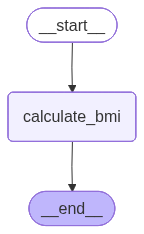

In [6]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [10]:
#defining state
class BMIstate(TypedDict):

  weight_kg:float
  height_m:float
  bmi:float

In [11]:
def calculate_bmi(state:BMIstate) -> BMIstate:
  weight=state['weight_kg']
  height=state['height_m']

  bmi=weight/(height**2)

  bmi=round(bmi,2)

  return {"bmi":bmi}


In [12]:
#define graph
graph=StateGraph(BMIstate)

#add nodes to graph
graph.add_node('calculate_bmi',calculate_bmi)

#add edges
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi',END)

#compile graph

workflow=graph.compile()

In [15]:
#execute the graph
initial_state={"weight_kg":80,"height_m":1.75}
final_state=workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.75, 'bmi': 26.12}


### **1b BMI calculator workflow with classification**

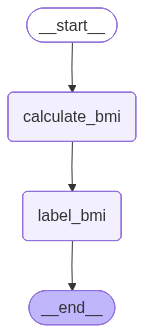

In [18]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [19]:
class BMIstate(TypedDict):
  weight_kg:float
  height_m:float
  bmi:float
  category:str

In [20]:
def calculate_bmi(state:BMIstate) -> BMIstate:
  weight=state['weight_kg']
  height=state['height_m']

  bmi=weight/(height**2)

  bmi=round(bmi,2)

  return {"bmi":bmi}


def label_bmi(state:BMIstate)->BMIstate:
  bmi=state['bmi']
  if bmi < 18.5:
      category= "Underweight"
  elif 18.5 <= bmi < 25:
      category = "Normal"
  elif 25 <= bmi < 30:
      category = "Overweight"
  else:
      category = "Obese"

  return {'category':category}



In [23]:
#define graph
graph=StateGraph(BMIstate)

#add nodes
graph.add_node('calculate_bmi',calculate_bmi)
graph.add_node('label_bmi',label_bmi)

#add edges
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi','label_bmi')
graph.add_edge('label_bmi',END)

#compile graph

workflow=graph.compile()

In [24]:
#executetionof graph
initial_state={"weight_kg":80,"height_m":1.75}
final_state=workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.75, 'bmi': 26.12, 'category': 'Overweight'}


### **2 LLM workflow**

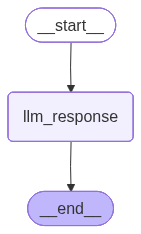

In [25]:
!pip install langchain-openai -qqq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.8/84.8 kB 2.5 MB/s eta 0:00:00


In [26]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_openai import ChatOpenAI

In [27]:
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

In [29]:
llm=ChatOpenAI(model='gpt-5-nano')

In [31]:
llm.invoke("capital of bihar").content

'Patna — the capital of Bihar, India.'

In [32]:
class LLMstate(TypedDict):

  question:str
  answer:str


In [33]:
def llm_response(state:LLMstate) ->LLMstate:
  question=state['question']
  prompt=f"answer the given question crisp {question}"

  answer=llm.invoke(prompt).content

  return {"answer":answer}

In [35]:
#define graph
graph=StateGraph(LLMstate)

#add nodes
graph.add_node('llm_response',llm_response)

#add edges
graph.add_edge(START,'llm_response')
graph.add_edge('llm_response',END)

#compile graph
workflow=graph.compile()

In [37]:
initial_state={"question":"capital of India"}
final_state=workflow.invoke(initial_state)
print(final_state)

{'question': 'capital of India', 'answer': 'New Delhi.'}


### **Prompt Chaining**

In [38]:
#input -> get_outline -> get_blog -> Output

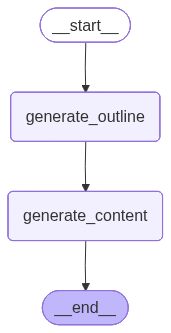

In [39]:
!pip install langchain-openai -qqq

In [40]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_openai import ChatOpenAI

In [41]:
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

In [42]:
llm=ChatOpenAI(model='gpt-5-nano')

In [43]:
class BlogState(TypedDict):
  title:str
  outline:str
  content:str

In [51]:
def generate_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = llm.invoke(prompt).content

    return {"outline":outline}


def generate_content(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'
    content = llm.invoke(prompt).content

    return {"content":content}

In [52]:
#define graph
graph=StateGraph(BlogState)

#add nodes
graph.add_node("generate_outline",generate_outline)
graph.add_node("generate_content",generate_content)

#add edges
graph.add_edge(START,'generate_outline')
graph.add_edge('generate_outline','generate_content')
graph.add_edge('generate_content',END)

#compile graph
workflow=graph.compile()

In [53]:
initial_state={"title":"AI develpent in india"}
final_state=workflow.invoke(initial_state)
print(final_state)

{'title': 'AI develpent in india', 'outline': "Here’s a detailed outline you can use for a blog series or a long-form post about AI development in India. It’s organized to cover context, ecosystem, sectors, challenges, and future directions, with optional subsections you can mix and match.\n\n- Working title ideas (choose one or combine):\n  - AI in India: Growth, Challenges, and the Path Ahead\n  - The Rise of Artificial Intelligence in India: Policy, Industry, and Innovation\n  - India’s AI Moment: Startups, Skills, and Societal Impact\n\n- Target audience\n  - Policymakers, researchers, startup founders, tech professionals, students, business leaders, and educators.\n\n- Core themes to emphasize\n  - Ecosystem coordination among government, academia, and industry\n  - Responsible AI, data governance, and ethics\n  - Inclusive growth, language and rural adoption, and social impact\n  - Global collaboration and India’s role in the AI value chain\n\nDetailed outline\n\n1) Introduction\